
# **King County Housing Prices – Multiple Linear Regression Analysis**

*This analysis uses multiple linear regression to examine how property characteristics influence housing prices in King County, Washington. The goal is to identify statistically significant predictors of home prices, evaluate model performance, and estimate property values using historical housing data.*

## Objectives

1. Explore and visualize the housing dataset.
2. Examine relationships between property characteristics and sale prices.
3. Fit a multiple linear regression model using a custom Python library.
4. Evaluate statistical significance and model performance.
5. Examine multicollinearity using Variance Inflation Factors (VIF).
6. Evaluate regression assumptions using diagnostic plots.
7. Generate housing price predictions and prediction intervals.
8. Interpret the results from a real estate business perspective.

## Business Problem

A real estate company wants to understand how **property characteristics relate to housing prices** to improve property valuation and support data-driven pricing decisions.

The primary objective is to identify which property characteristics are statistically significant predictors of sale prices and assess how accurately a multiple linear regression model can estimate property values.

### Key Business Questions

1. Which property characteristics are significantly associated with housing prices?
2. How much does each property characteristic contribute to predicted home prices when controlling for other variables?
3. Does multicollinearity affect the reliability of the regression coefficients?
4. How accurately can the model estimate housing prices?
5. How much uncertainty exists in the predicted property values?

**Approach:** Multiple linear regression will be used to analyze historical King County housing sales data, evaluate the significance of property characteristics, assess regression assumptions, and generate property price predictions to support real estate valuation decisions.


In [51]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2, t

from lm_manual_class import lm_manual

## 1. Dataset Overview

The dataset contains historical housing sales in **King County, Washington**, from May 2014 to May 2015, including property characteristics and their corresponding sale prices.

For this analysis, six variables will be considered:

- **Price:** Final sale price of the property in dollars.
- **Sqft_living:** Interior living space measured in square feet.
- **Bedrooms:** Number of bedrooms in the property.
- **Bathrooms:** Number of bathrooms in the property.
- **Grade:** Overall construction and design quality.
- **Condition:** Overall condition of the property.

**Price** is the dependent variable, while the remaining five variables are the independent variables used to predict housing prices.

Multiple linear regression will be used to evaluate how these property characteristics are associated with sale prices while controlling for the other predictors.

In [52]:
# Load and inspect dataset
url = "https://raw.githubusercontent.com/46n/king-county-house-sales-analysis/main/data/housing.csv"

df = pd.read_csv(url, index_col=0)

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
df[["price", "sqft_living", "bedrooms",
    "bathrooms", "grade", "condition"]].describe()

Dataset Shape: (21613, 21)

Missing Values:
id                0
date              0
price             0
bedrooms         13
bathrooms        10
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
grade             0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
zipcode           0
lat               0
long              0
sqft_living15     0
sqft_lot15        0
dtype: int64

Summary Statistics:


,price,sqft_living,bedrooms,bathrooms,grade,condition
count,2.161300e+04,21613.000000,21600.000000,21603.000000,21613.000000,21613.000000
mean,5.400881e+05,2079.899736,3.372870,2.115736,7.656873,3.409430
std,3.671272e+05,918.440897,0.926657,0.768996,1.175459,0.650743
min,7.500000e+04,290.000000,1.000000,0.500000,1.000000,1.000000
25%,3.219500e+05,1427.000000,3.000000,1.750000,7.000000,3.000000
50%,4.500000e+05,1910.000000,3.000000,2.250000,7.000000,3.000000
75%,6.450000e+05,2550.000000,4.000000,2.500000,8.000000,4.000000
max,7.700000e+06,13540.000000,33.000000,8.000000,13.000000,5.000000



## 2. Exploratory Data Analysis (EDA)

Before fitting a multiple linear regression model, exploratory data analysis is conducted to examine the relationships between **housing prices and property characteristics**.

The analysis uses a **scatterplot matrix, Pearson correlation heatmap, and boxplots** to explore the selected variables.

The objectives are to:

- **Identify relationships:** Examine how property characteristics relate to housing prices.
- **Assess linearity:** Determine whether relationships appear approximately linear.
- **Measure correlation:** Use a Pearson correlation heatmap to evaluate the strength and direction of relationships between variables.
- **Investigate multicollinearity:** Identify highly correlated predictors that may affect regression coefficient estimates.
- **Detect outliers:** Identify unusual observations that could influence the regression model.
- **Examine distributions:** Evaluate the variability, central tendency, and spread of the selected variables.

The scatterplot matrix uses a random sample of **2,000 observations** for visualization, while the correlation analysis uses the **full dataset**.

These exploratory techniques help evaluate whether multiple linear regression is an appropriate modeling approach.


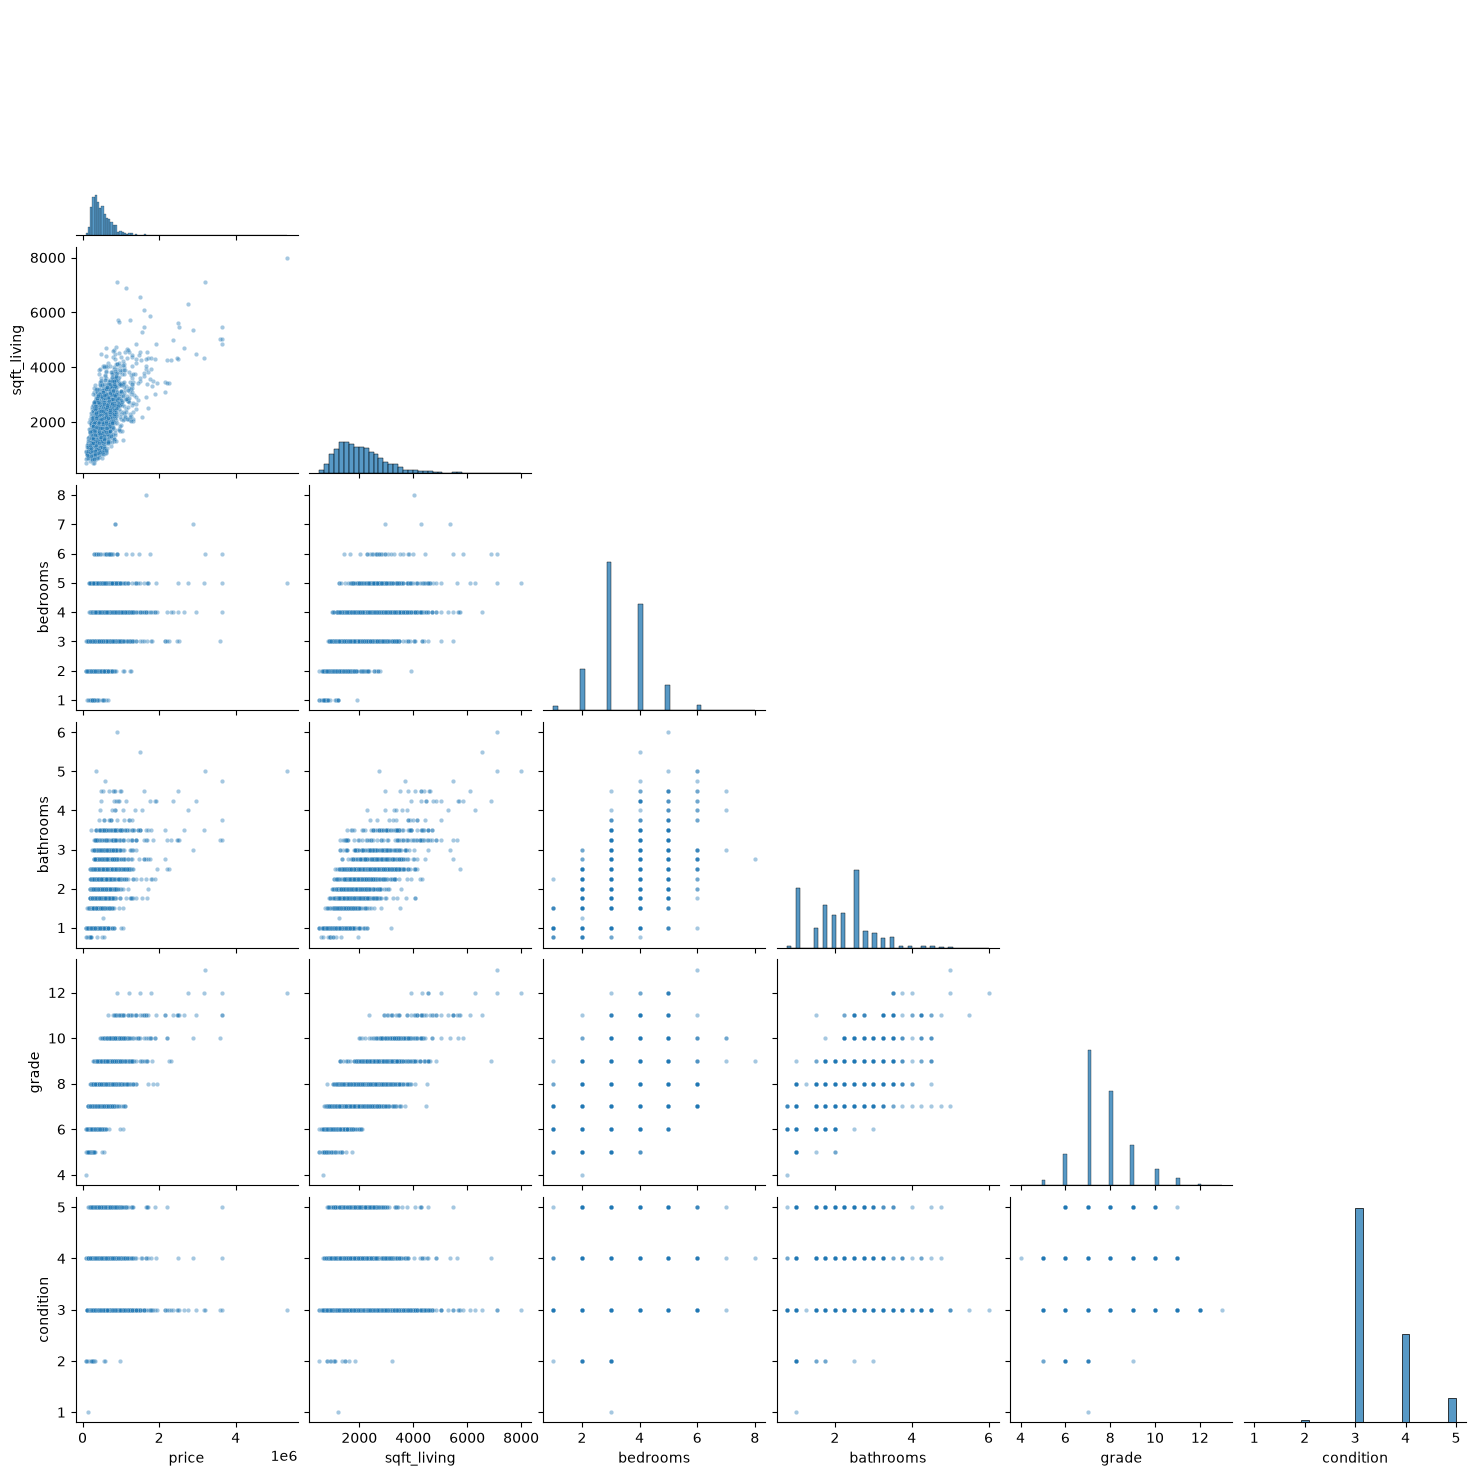

In [53]:
# Variables used in multiple regression
columns = ["price", "sqft_living", "bedrooms",
           "bathrooms", "grade", "condition"]

# Sample for visualization only
sample = df[columns].sample(n=2000, random_state=42)

# Scatterplot matrix
sns.pairplot(
    sample,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.4, "s": 10}

)

plt.show()


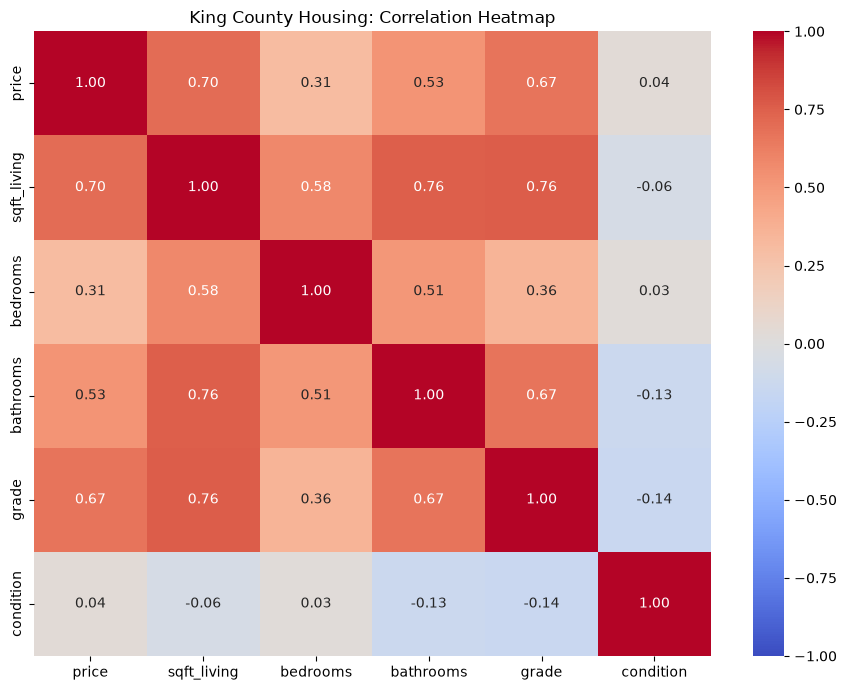

In [54]:
# Pearson correlation matrix
correlation = df[columns].corr()

# Correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("King County Housing: Correlation Heatmap")
plt.tight_layout()
plt.show()


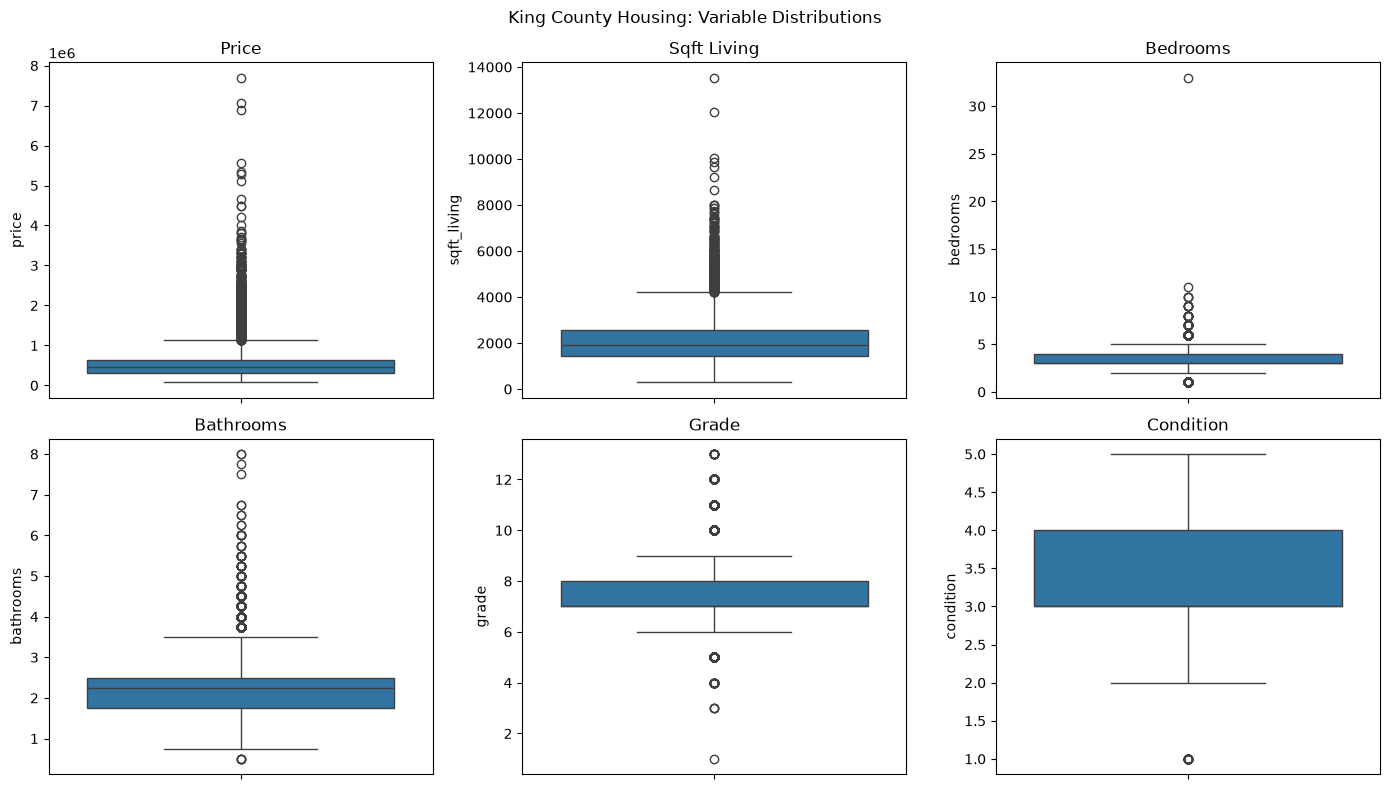

In [55]:
# Boxplots for regression variables
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, col in zip(axes.flat, columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel(col)

plt.suptitle("King County Housing: Variable Distributions")
plt.tight_layout()
plt.show()

### 2 Exploratory Data Analysis Results

The exploratory data analysis reveals several important relationships between **housing prices and property characteristics**, along with potential issues to investigate during regression modeling.

#### Scatterplot Matrix Results

- **Living Area:** Larger properties generally have higher sale prices, indicating a positive relationship.
- **Grade:** Properties with higher construction grades tend to have higher sale prices.
- **Bedrooms and Bathrooms:** Both variables exhibit positive relationships with living area, suggesting that larger homes generally contain more rooms.
- **Condition:** No strong linear relationship with housing prices is visually apparent.
- **Outliers:** Several unusually expensive properties and large homes are present.

#### Correlation Analysis

The Pearson correlation heatmap identified the following relationships with housing prices:

| Variable | Correlation (r) |
|---|---|
| Living Area | 0.70 |
| Grade | 0.67 |
| Bathrooms | 0.53 |
| Bedrooms | 0.31 |
| Condition | 0.04 |

**Living area and construction grade** exhibit the strongest positive correlations with housing prices.

Potential multicollinearity was also identified between several predictors:

- **Living Area and Bathrooms:** r = 0.76
- **Living Area and Grade:** r = 0.76
- **Bathrooms and Grade:** r = 0.67

These relationships will be investigated further using **Variance Inflation Factors (VIF)**.

#### Boxplot Analysis

The boxplots reveal the following distribution characteristics:

- **Housing Prices:** Strong right-skewness, with numerous high-value outliers.
- **Living Area:** Right-skewed distribution, with several unusually large properties.
- **Bedrooms:** Most properties contain approximately 3–4 bedrooms, with some extreme observations.
- **Bathrooms:** Most properties have approximately 2–3 bathrooms, with several higher-value outliers.
- **Grade:** Most properties have construction grades between 7 and 8, with unusually high and low grades present.
- **Condition:** Most properties are rated between 3 and 4, with relatively limited variability.

#### Overall EDA Conclusion

The analysis suggests that **living area, construction grade, and bathroom count** may be important predictors of housing prices.

However, the presence of **outliers, skewed distributions, and potentially correlated predictors** raises concerns that should be evaluated during regression modeling.

Multiple linear regression will be used to estimate the independent association of each property characteristic with housing prices while controlling for the remaining variables.

Further analysis will include **VIF calculations, regression diagnostics, and hypothesis testing** to assess model reliability.

## 3. Multiple Linear Regression Model

A multiple linear regression model is fitted to examine how **property characteristics are associated with housing prices** in King County, Washington.

The model uses the following variables:

**Dependent Variable (y):**
- **Price:** Property sale price in dollars.

**Independent Variables (X):**
- **Sqft_living:** Interior living area in square feet.
- **Bedrooms:** Number of bedrooms.
- **Bathrooms:** Number of bathrooms.
- **Grade:** Overall construction and design quality.
- **Condition:** Overall property condition.

The model estimates how each property characteristic is associated with housing prices **while holding the other independent variables constant**.

In [56]:
X = df[["sqft_living", "bedrooms", "bathrooms",
        "grade", "condition"]]
y = df["price"]
model = lm_manual(X, y)
model.summary()

OLS Summary:
------------------------------------------------------------------------------------------------------------
Response variable:   price
Predictors:          5
Observations used:   21597
Rows removed:        16
------------------------------------------------------------------------------------------------------------
Coefficient Estimates
Term                  Estimate    Std. Error     t value       P-value                        95% CI
------------------------------------------------------------------------------------------------------------
Intercept         -745649.1095    18187.9273    -40.9969             0  (-781298.7904, -709999.4287)
sqft_living           219.3701        3.5519     61.7619             0          (212.4082, 226.3321)
bedrooms           -43588.2922     2275.8249    -19.1527     4.322e-81    (-48049.0771, -39127.5074)
bathrooms          -18028.3674     3460.2796     -5.2101     1.905e-07    (-24810.7711, -11245.9637)
grade              103510.1924  

### 3 Regression Results and Interpretation

The multiple linear regression model was fitted using **21,597 observations** and five independent variables.

#### Estimated Regression Equation

$$
\begin{aligned}
\widehat{Price} =\;& -745649.11 \\
&+ 219.37(SqftLiving)\\
&- 43588.29(Bedrooms)\\
&- 18028.37(Bathrooms)\\
&+ 103510.19(Grade)\\
&+ 65104.85(Condition)
\end{aligned}
$$

#### Coefficient Interpretation

Holding all other predictors constant:

- **Living Area:** Each additional square foot is associated with approximately **$219.37 higher predicted price**.
- **Bedrooms:** Each additional bedroom is associated with approximately **$43,588 lower predicted price**.
- **Bathrooms:** Each additional bathroom is associated with approximately **$18,028 lower predicted price**.
- **Grade:** Each one-point increase in construction grade is associated with approximately **$103,510 higher predicted price**.
- **Condition:** Each one-point increase in property condition is associated with approximately **$65,105 higher predicted price**.

The negative bedroom and bathroom coefficients require further investigation because these variables are correlated with other property characteristics.

#### Hypothesis Testing

For each independent variable:

$$
H_0: \beta_j = 0
$$

$$
H_a: \beta_j \neq 0
$$

**Significance Level:** $\alpha = 0.05$

All five predictors have **p-values < 0.05**, indicating statistically significant associations with housing prices after controlling for the other variables.

#### Overall Model Significance

The overall F-test evaluates whether at least one predictor contributes to the regression model.

$$
H_0: \beta_1 = \beta_2 = \beta_3 = \beta_4 = \beta_5 = 0
$$

$$
H_a: \text{At least one slope coefficient is nonzero}
$$

**Results:**
- **F-statistic:** 5414.6434
- **p-value:** < 0.001
- **R-squared:** 0.5563
- **Adjusted R-squared:** 0.5562
- **Residual Standard Error:** $244,571.63

#### Conclusion

The overall regression model is statistically significant and explains approximately **55.63% of the variation in housing prices**.

Living area and construction grade exhibit strong positive conditional associations with property prices.

However, the negative coefficients for bedrooms and bathrooms, along with previously identified correlations between predictors, suggest that **multicollinearity and model specification should be investigated further**.

Variance Inflation Factors (VIF) and regression diagnostics will be used to evaluate these concerns.

## 4. Multicollinearity Analysis

Variance Inflation Factors (VIF) are calculated to investigate multicollinearity among the independent variables.

Multicollinearity occurs when independent variables are strongly linearly related, potentially increasing the uncertainty of regression coefficient estimates.

The purpose of this analysis is to:

- **Identify multicollinearity:** Determine whether predictors are strongly related to one another.
- **Evaluate coefficient reliability:** Assess whether multicollinearity may affect standard errors and statistical significance.
- **Investigate negative coefficients:** Examine whether relationships among predictors may contribute to the negative bedroom and bathroom coefficients.

### VIF Interpretation

- **VIF = 1:** No linear association with the other predictors.
- **VIF between 1 and 5:** Generally acceptable multicollinearity.
- **VIF between 5 and 10:** Potentially concerning multicollinearity.
- **VIF > 10:** Often considered severe multicollinearity.

These thresholds are guidelines rather than strict statistical rules.

In [57]:
# Check multicollinearity
model.vif()

,Predictor,VIF
0,sqft_living,3.8394
1,bedrooms,1.6045
2,bathrooms,2.5563
3,grade,2.6417
4,condition,1.0435


### 4.1 Multicollinearity Results

Variance Inflation Factors (VIF) were calculated for all five independent variables to assess multicollinearity.

#### Results

- **Living Area:** VIF = 3.8394
- **Bedrooms:** VIF = 1.6045
- **Bathrooms:** VIF = 2.5563
- **Grade:** VIF = 2.6417
- **Condition:** VIF = 1.0435

#### Interpretation

All VIF values are below the commonly used threshold of 5, suggesting that **multicollinearity is not a major concern** for this model.

Living area exhibits the highest VIF, indicating some correlation with other predictors, particularly bathrooms and construction grade.

Although bedrooms and bathrooms have negative regression coefficients, their relatively low VIF values suggest that severe multicollinearity alone does not explain these results.

#### Conclusion

The VIF analysis provides no evidence of severe multicollinearity among the selected predictors.

**All five independent variables will be retained** for the next stage of regression diagnostics.

## 5. Regression Diagnostics

Regression diagnostics are performed to evaluate the assumptions of the multiple linear regression model and identify potential issues affecting model reliability.

Four diagnostic plots are examined:

1. **Residuals vs. Fitted:** Evaluates linearity and checks for patterns or nonconstant error variance.
2. **Normal Q-Q Plot:** Assesses whether the residuals approximately follow a normal distribution.
3. **Scale-Location Plot:** Examines whether residual variance remains constant across fitted housing prices.
4. **Residuals vs. Leverage:** Identifies potentially influential observations using leverage and Cook's distance.

These diagnostics help determine whether the model provides reliable estimates of housing prices and whether additional statistical adjustments are necessary.

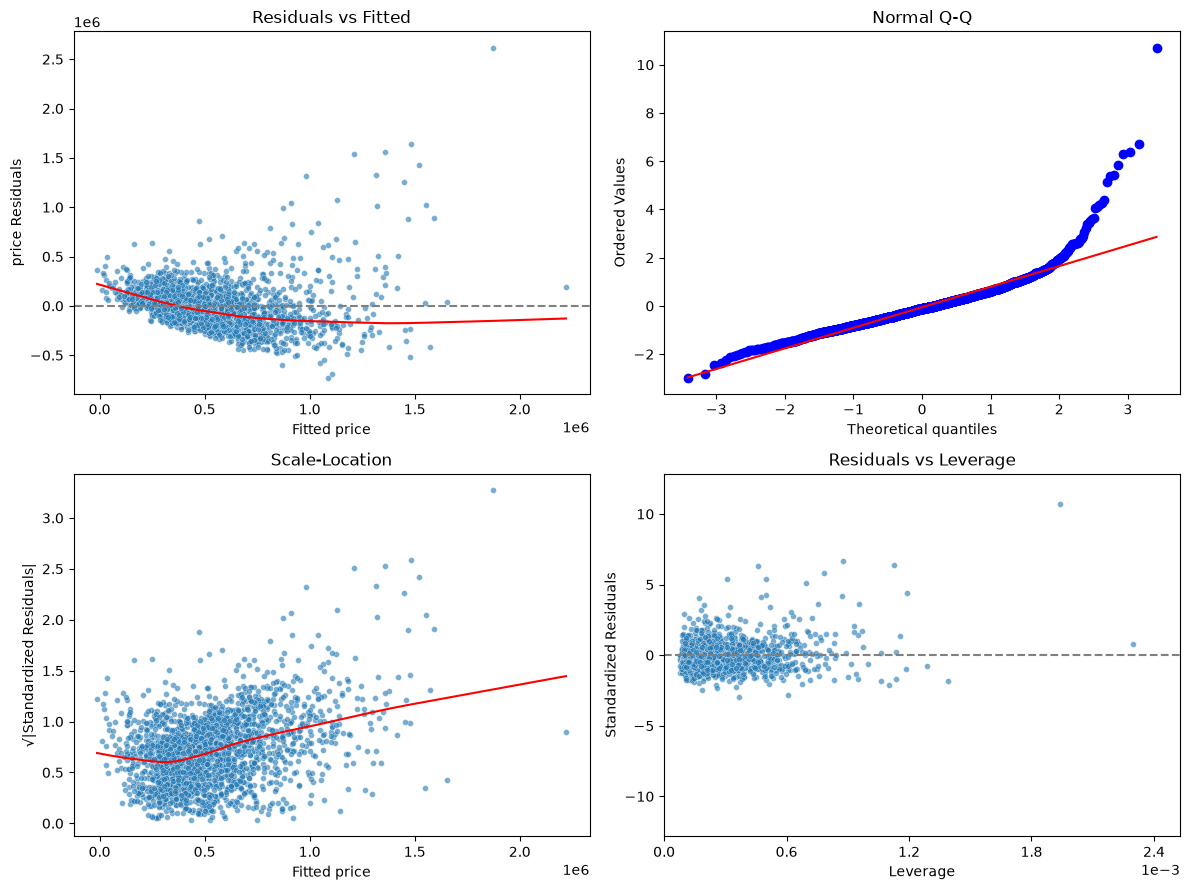

In [58]:
# Multiple regression diagnostics
model.plot_diagnostics(max_points=2200)


### 5.1 Regression Diagnostic Results

The diagnostic plots reveal several potential violations of the multiple linear regression assumptions.

#### Key Findings

- **Residuals vs. Fitted:** The curved smoothing line suggests possible nonlinearity, while increasing residual spread indicates potential heteroscedasticity.
- **Normal Q-Q:** Significant deviations in the upper tail suggest that residuals are not normally distributed, with several unusually large positive residuals.
- **Scale-Location:** The upward trend provides visual evidence of nonconstant error variance.
- **Residuals vs. Leverage:** Several observations exhibit large standardized residuals. Cook's distance should be examined to identify potentially influential observations.

#### Overall Assessment

Although the regression model explains approximately **55.63% of the variation in housing prices**, the diagnostic plots indicate potential violations of the linearity, normality, and constant variance assumptions.

These findings suggest that conventional OLS statistical inference and prediction intervals may be unreliable.

Further analysis using the **Breusch-Pagan test, heteroscedasticity-robust standard errors, and influence diagnostics** is recommended.

Alternative model specifications, such as a logarithmic transformation of housing prices, may also improve model performance.


## 6. Breusch-Pagan Test for Heteroscedasticity

The regression diagnostic plots suggest that residual variance increases as predicted housing prices increase. To formally investigate this, the **Breusch-Pagan test** is conducted.

### Hypotheses

$$
H_0: \text{The error variance is constant (homoscedasticity)}
$$

$$
H_a: \text{The error variance is not constant (heteroscedasticity)}
$$

**Significance Level:** $\alpha = 0.05$

- **p-value < 0.05:** Reject the null hypothesis, indicating evidence of heteroscedasticity.
- **p-value ≥ 0.05:** Fail to reject the null hypothesis; insufficient evidence of heteroscedasticity.

In [59]:
# Use the observations retained by the original model
X_aux = pd.DataFrame(
    model.X_design[:, 1:],
    columns=model.feature_names
)

# Fit auxiliary regression using squared residuals
aux_model = lm_manual(X_aux, model.residuals ** 2)

# Calculate Breusch-Pagan LM statistic
n = model.n
LM = n * aux_model.R_squared

# Calculate p-value using 5 degrees of freedom
p_value = chi2.sf(LM, df=5)

# Display results
print("Breusch-Pagan Test")
print("-------------------------")
print(f"LM Statistic: {LM:.4f}")
print(f"P-value: {p_value:.6g}")

if p_value < 0.05:
    print("Reject H0: Evidence of heteroscedasticity")
else:
    print("Fail to reject H0: Insufficient evidence of heteroscedasticity")


Breusch-Pagan Test
-------------------------
LM Statistic: 2284.6415
P-value: 0
Reject H0: Evidence of heteroscedasticity



### 6 Breusch-Pagan Test Results

The Breusch-Pagan test was conducted to investigate the presence of heteroscedasticity in the multiple linear regression model.

**Test Results:**
- **LM Statistic:** 2284.6415
- **Degrees of Freedom:** 5
- **P-value:** < 0.001
- **Significance Level:** 0.05

#### Interpretation

Since the **p-value < 0.05**, we reject the null hypothesis of constant error variance.

There is strong statistical evidence of **heteroscedasticity**, indicating that the variance of regression errors is not constant.

This finding supports the increasing residual spread observed in the Residuals vs. Fitted and Scale-Location diagnostic plots.

#### Implications

The presence of heteroscedasticity suggests that conventional OLS standard errors, confidence intervals, and hypothesis tests may be unreliable.

**HC3 heteroscedasticity-robust standard errors** will be calculated to improve the reliability of statistical inference.

However, HC3 does not correct potential nonlinearity or other model specification issues.


In [60]:

from scipy.stats import t

# Use values from regression class
X_design = model.X_design
residuals = model.residuals
betas = model.betas

# Calculate (X'X)^-1
XtX_inv = np.linalg.inv(X_design.T @ X_design)

# Calculate leverage values without creating full H matrix
leverage = np.sum(
    (X_design @ XtX_inv) * X_design, axis=1
)

# Calculate HC3 weights
weights = residuals**2 / (1 - leverage)**2

# Calculate robust covariance matrix
weighted_X = X_design * weights[:, None]

cov_HC3 = XtX_inv @ (X_design.T @ weighted_X) @ XtX_inv

# Robust standard errors
se_HC3 = np.sqrt(np.diag(cov_HC3))

# Robust t-statistics
t_HC3 = betas / se_HC3

# Robust p-values
p_HC3 = 2 * t.sf(np.abs(t_HC3), df=model.df)

# 95% confidence intervals
t_critical = t.ppf(0.975, df=model.df)

ci_lower = betas - t_critical * se_HC3
ci_upper = betas + t_critical * se_HC3


hc3_results = pd.DataFrame({
    "Coefficient": betas,
    "Robust SE": se_HC3,
    "t-value": t_HC3,
    "p-value": p_HC3,
    "CI Lower": ci_lower,
    "CI Upper": ci_upper
}, index=model.coefficient_names)

hc3_results.round(4)



,Coefficient,Robust SE,t-value,p-value,CI Lower,CI Upper
Intercept,-745649.1095,28396.8787,-26.2581,0.0000,-801309.0893,-689989.1298
sqft_living,219.3701,10.6491,20.5999,0.0000,198.4971,240.2431
bedrooms,-43588.2922,5462.0273,-7.9802,0.0000,-54294.2692,-32882.3153
bathrooms,-18028.3674,4642.0239,-3.8837,0.0001,-27127.0772,-8929.6576
grade,103510.1924,4141.8338,24.9914,0.0000,95391.8921,111628.4926
condition,65104.8474,2751.5963,23.6608,0.0000,59711.5154,70498.1794



### 7 HC3 Robust Standard Error Results

Following the Breusch-Pagan test, **HC3 robust standard errors** were calculated to account for heteroscedasticity in the multiple linear regression model.

The estimated regression coefficients remained unchanged, while their standard errors, t-statistics, p-values, and confidence intervals were adjusted.

#### HC3 Results

| Predictor | Coefficient | Robust SE | P-value |
|---|---:|---:|---:|
| Living Area | 219.37 | 10.65 | < 0.001 |
| Bedrooms | -43,588.29 | 5,462.03 | < 0.001 |
| Bathrooms | -18,028.37 | 4,642.02 | 0.0001 |
| Grade | 103,510.19 | 4,141.83 | < 0.001 |
| Condition | 65,104.85 | 2,751.60 | < 0.001 |

#### Interpretation

All five independent variables remain **statistically significant at the 0.05 level** after applying HC3 robust standard errors.

Holding other property characteristics constant:

- **Living Area:** Each additional square foot is associated with approximately $219 higher predicted housing prices.
- **Bedrooms:** Each additional bedroom is associated with approximately $43,588 lower predicted prices.
- **Bathrooms:** Each additional bathroom is associated with approximately $18,028 lower predicted prices.
- **Grade:** A one-point increase in construction grade is associated with approximately $103,510 higher predicted prices.
- **Condition:** A one-point increase in property condition is associated with approximately $65,105 higher predicted prices.

#### Conclusion

The HC3 results confirm that all five predictors retain statistically significant associations with housing prices after accounting for heteroscedasticity.

However, the regression diagnostics also identified **nonlinearity, extreme residuals, and potential influential observations**, which are not corrected by robust standard errors.

Therefore, the model provides useful insights into historical housing prices, but additional model refinement may improve its reliability for property valuation.


## 8. Cook's Distance Analysis

Cook's distance is used to identify **potentially influential observations** that may disproportionately affect the estimated regression coefficients.

The analysis evaluates:

- **Influential Observations:** Identify properties that may significantly affect regression estimates.
- **Outliers:** Investigate observations with unusually large regression residuals.
- **Leverage:** Examine properties with unusual combinations of predictor values.
- **Model Reliability:** Determine whether a small number of observations may strongly influence the fitted model.

A commonly used screening threshold is:

$$
D_i > \frac{4}{n}
$$

where $n$ is the number of observations.

Observations exceeding this threshold will be flagged for further investigation rather than automatically removed.

In [61]:
# Cook's distance results
threshold = 4 / model.n

print(f"Threshold: {threshold:.6f}")
print(f"Maximum Cook's Distance: {np.nanmax(model.cooks_distance):.6f}")
print(f"Observations Above Threshold: {np.sum(model.cooks_distance > threshold)}")


Threshold: 0.000185
Maximum Cook's Distance: 0.529382
Observations Above Threshold: 1042


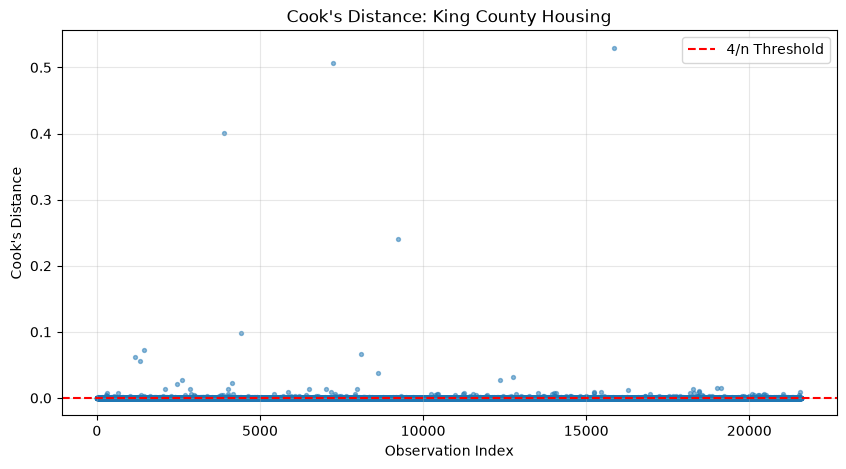

In [62]:
# Plot cooks distance

plt.figure(figsize=(10, 5))

plt.scatter(
    range(model.n),
    model.cooks_distance,
    alpha=0.5,
    s=8
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="4/n Threshold"
)

plt.title("Cook's Distance: King County Housing")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [63]:
# Find 10 largest Cook's distances
top_10 = np.argsort(
    np.nan_to_num(model.cooks_distance, nan=-1)
)[-10:][::-1]

results = pd.DataFrame({
    "Observation": top_10,
    "Cook's Distance": model.cooks_distance[top_10],
    "Leverage": model.leverage[top_10],
    "Residual": model.residuals[top_10]
})

results.round(5)


,Observation,Cook's Distance,Leverage,Residual
0,15856,0.52938,0.07697,1.450137e+06
1,7245,0.50679,0.00844,4.601944e+06
2,3910,0.40147,0.00680,4.570815e+06
3,9245,0.24042,0.00458,4.321381e+06
4,4407,0.09856,0.00371,3.078101e+06
5,1446,0.07312,0.00253,3.211334e+06
6,8085,0.06690,0.00491,2.201117e+06
7,1162,0.06225,0.00251,2.974448e+06
8,1313,0.05637,0.00186,3.291662e+06
9,8629,0.03711,0.00194,2.615101e+06


### 8 Cook's Distance Results

Cook's distance was calculated to identify potentially influential observations in the multiple linear regression model.

#### Results

- **Observations Analyzed:** 21,597
- **Cook's Distance Threshold (4/n):** 0.000185
- **Observations Above Threshold:** 1,042
- **Percentage Flagged:** 4.82%
- **Maximum Cook's Distance:** 0.529382

#### Interpretation

The analysis identified **1,042 observations exceeding the Cook's distance screening threshold**, suggesting that several properties may influence the estimated regression coefficients.

The most influential observation had a Cook's distance of approximately **0.5294**, while several others exhibited relatively large residuals or leverage values.

These observations may represent unusually expensive properties, exceptionally large homes, or properties with uncommon characteristics.

#### Conclusion

The Cook's distance analysis suggests that **potentially influential observations are present** in the housing dataset.

However, observations exceeding the screening threshold are not necessarily errors and should not automatically be removed.

Further investigation may help determine whether influential observations substantially affect model estimates and predictions.

For the current analysis, all valid observations will be retained unless there is a justified reason for excluding them.

## 9. Sensitivity Analysis

A sensitivity analysis is conducted to evaluate how influential observations affect the multiple linear regression results.

The analysis compares two models:

1. **Original Model:** All 21,597 valid observations.
2. **Modified Model:** Excludes the 10 observations with the highest Cook's distance, leaving 21,587 observations.

The purpose is to:

- **Assess coefficient stability:** Determine whether regression coefficients change substantially.
- **Evaluate model performance:** Compare R-squared and residual standard error.
- **Investigate influential observations:** Determine whether a small number of properties disproportionately influence the results.
- **Assess robustness:** Evaluate whether the main findings remain consistent after excluding influential observations.

The excluded observations are removed only for sensitivity testing and will remain in the original regression model.

In [64]:
# Identify the 10 most influential observations
top_10 = np.argsort(model.cooks_distance)[-10:]

# Create a mask excluding these observations
keep = np.ones(model.n, dtype=bool)
keep[top_10] = False

# Create cleaned regression data
X_clean = pd.DataFrame(
    model.independent[keep],
    columns=model.feature_names
)

y_clean = pd.Series(
    model.dependent[keep],
    name=model.y_name
)

# Fit modified regression model
sensitivity_model = lm_manual(X_clean, y_clean)

In [65]:

# Compare original and modified coefficients
comparison = pd.DataFrame({
    "Original": model.betas,
    "Without Top 10": sensitivity_model.betas
}, index=model.coefficient_names)

# Percentage change
comparison["Change (%)"] = (
    (comparison["Without Top 10"] - comparison["Original"])
    / np.abs(comparison["Original"]) * 100
)

comparison.round(2)


,Original,Without Top 10,Change (%)
Intercept,-745649.11,-767189.28,-2.89
sqft_living,219.37,197.76,-9.85
bedrooms,-43588.29,-40217.06,7.73
bathrooms,-18028.37,-16629.14,7.76
grade,103510.19,109991.45,6.26
condition,65104.85,65395.19,0.45


In [66]:
# Compare model performance
performance = pd.DataFrame({
    "Original Model": [
        model.n,
        model.R_squared,
        model.adjusted_r_squared,
        model.rse
    ],
    "Without Top 10": [
        sensitivity_model.n,
        sensitivity_model.R_squared,
        sensitivity_model.adjusted_r_squared,
        sensitivity_model.rse
    ]
}, index=[
    "Observations",
    "R-squared",
    "Adjusted R-squared",
    "Residual Standard Error"
])

performance.round(4)


,Original Model,Without Top 10
Observations,21597.0000,21587.0000
R-squared,0.5563,0.5573
Adjusted R-squared,0.5562,0.5572
Residual Standard Error,244571.6292,233247.3991



### 9 Sensitivity Analysis Results

A sensitivity analysis was conducted by removing the **10 observations with the highest Cook's distance** and refitting the multiple linear regression model.

The original model contained **21,597 observations**, while the modified model contained **21,587 observations**.

#### Coefficient Comparison

- **Living Area:** Decreased by 9.85%, showing the greatest relative sensitivity among predictors.
- **Bedrooms:** Increased by 7.73%, becoming less negative.
- **Bathrooms:** Increased by 7.76%, becoming less negative.
- **Grade:** Increased by 6.26%.
- **Condition:** Increased by only 0.45%, indicating a highly stable coefficient.

All five predictors retained their original coefficient signs.

#### Model Performance

- **R-squared:** Increased slightly from 0.5563 to 0.5573.
- **Adjusted R-squared:** Increased from 0.5562 to 0.5572.
- **Residual Standard Error:** Decreased from approximately $244,572 to $233,247.

The changes indicate that the excluded observations influence model estimates, particularly living area, bedrooms, bathrooms, and grade.

#### Conclusion

The sensitivity analysis suggests that the regression model is **reasonably stable in terms of coefficient direction and overall explanatory power**.

Although some coefficient estimates changed noticeably, the overall relationships remained consistent after excluding the 10 most influential observations.

The improvement in model performance should be interpreted cautiously because the models were fitted using slightly different observations.

**Overall, the findings suggest that a small number of influential properties affect coefficient magnitudes but do not fundamentally alter the main regression conclusions.**

The original model will be retained for subsequent analysis, as influential observations should not be removed without sufficient justification.



## 10. Housing Price Predictions

The fitted multiple linear regression model is used to estimate housing prices based on five property characteristics: **living area, bedrooms, bathrooms, grade, and condition**.

Five hypothetical properties are evaluated to demonstrate the model's potential application in real estate valuation.

The analysis includes:

- **Point Predictions:** Estimate housing prices for different property characteristics.
- **95% Prediction Intervals:** Evaluate uncertainty surrounding individual property valuations.
- **Prediction Visualization:** Examine how predicted housing prices change with living area while holding other characteristics constant.

The predictions are based on historical King County housing data from 2014–2015.

Because regression diagnostics identified heteroscedasticity and other model assumption concerns, the conventional prediction intervals should be interpreted cautiously.


In [67]:
# Hypothetical houses
houses = pd.DataFrame({
    "sqft_living": [1200, 1800, 2400, 3000, 4000],
    "bedrooms": [2, 3, 3, 4, 5],
    "bathrooms": [1, 2, 2.5, 3, 4],
    "grade": [6, 7, 8, 9, 10],
    "condition": [3, 3, 3, 4, 4]
})

# Predict house prices using custom regression model
predictions = model.predict(houses)

# Create prediction table
prediction_results = houses.copy()
prediction_results["Predicted Price ($)"] = predictions

prediction_results.round(2)


,sqft_living,bedrooms,bathrooms,grade,condition,Predicted Price ($)
0,1200,2,1.0,6,3,228765.80
1,1800,3,2.0,7,3,402281.41
2,2400,3,2.5,8,3,628399.50
3,3000,4,3.0,9,4,876034.14
4,4000,5,4.0,10,4,1137297.81


In [68]:

# Generate 95% prediction intervals
interval_results = model.predict(houses, interval="prediction")

interval_results.round(2)


,sqft_living,bedrooms,bathrooms,grade,condition,Predicted price,Lower Bound,Upper Bound
0,1200.0,2.0,1.0,6.0,3.0,228765.80,-250679.27,708210.86
1,1800.0,3.0,2.0,7.0,3.0,402281.41,-77119.86,881682.68
2,2400.0,3.0,2.5,8.0,3.0,628399.50,148996.54,1107802.46
3,3000.0,4.0,3.0,9.0,4.0,876034.14,396612.90,1355455.38
4,4000.0,5.0,4.0,10.0,4.0,1137297.81,657818.48,1616777.14


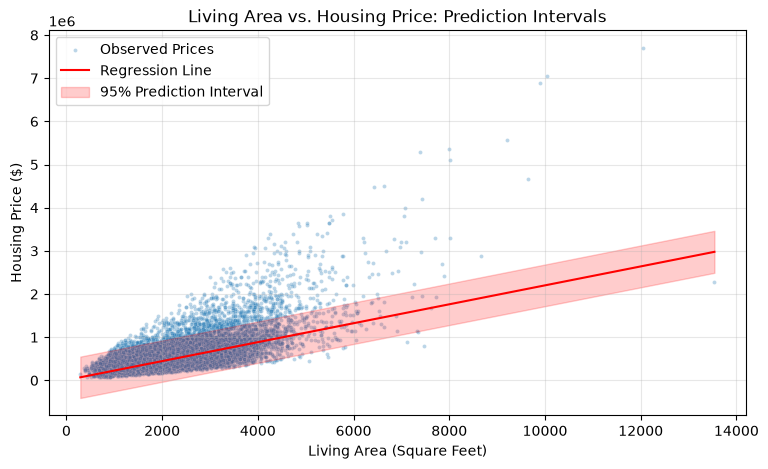

In [69]:
# Generate living area values
x_line = np.linspace(df["sqft_living"].min(),
                     df["sqft_living"].max(), 200)

# Hold other predictors constant
line_houses = pd.DataFrame({
    "sqft_living": x_line,
    "bedrooms": 3,
    "bathrooms": 2,
    "grade": 7,
    "condition": 3
})

# Generate predictions and intervals
intervals = model.predict(line_houses, interval="prediction")

lower = intervals.iloc[:, -2].to_numpy()
upper = intervals.iloc[:, -1].to_numpy()

# Plot observed housing prices
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="sqft_living", y="price",
                alpha=0.3, s=8, label="Observed Prices")

# Plot regression line
plt.plot(x_line, model.predict(line_houses),
         color="red", label="Regression Line")

# Plot prediction intervals
plt.fill_between(x_line, lower, upper,
                 alpha=0.2, color="red",
                 label="95% Prediction Interval")

plt.title("Living Area vs. Housing Price: Prediction Intervals")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Housing Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### 10.1 Housing Price Prediction Results

The multiple linear regression model was used to estimate housing prices for five hypothetical properties with varying characteristics.

#### Prediction Results

| Living Area | Bedrooms | Bathrooms | Grade | Condition | Predicted Price |
|---|---|---|---|---|---|
| 1,200 sqft | 2 | 1 | 6 | 3 | $228,766 |
| 1,800 sqft | 3 | 2 | 7 | 3 | $402,281 |
| 2,400 sqft | 3 | 2.5 | 8 | 3 | $628,400 |
| 3,000 sqft | 4 | 3 | 9 | 4 | $876,034 |
| 4,000 sqft | 5 | 4 | 10 | 4 | $1,137,298 |

#### Prediction Interpretation

The results show that properties with larger living areas and higher construction grades generally have higher predicted sale prices.

The prediction visualization illustrates the positive relationship between living area and housing prices while holding the remaining property characteristics constant.

The **95% prediction intervals** illustrate uncertainty in individual property valuations. However, the regression diagnostics identified heteroscedasticity, non-normal residuals, and potential nonlinearity, which may affect the reliability of these intervals.



## 11. Business Interpretation and Conclusion

### Business Interpretation

The multiple linear regression analysis identified **statistically significant relationships between housing prices and all five selected property characteristics** in King County, Washington.

The regression results indicate that:

- **Living Area:** Each additional square foot is associated with approximately **$219 higher predicted housing prices**, holding other characteristics constant.
- **Construction Grade:** A one-point increase in grade is associated with approximately **$103,510 higher predicted prices**.
- **Property Condition:** A one-point increase in condition is associated with approximately **$65,105 higher predicted prices**.
- **Bedrooms and Bathrooms:** Both exhibit negative coefficients after controlling for the other predictors, suggesting that their relationships with housing prices are more complex than their individual correlations indicate.
- **Model Performance:** The model explains approximately **55.63% of the variation in housing prices**.
- **Statistical Significance:** All five predictors remain statistically significant after applying HC3 heteroscedasticity-robust standard errors.

### Business Recommendations

Based on these findings, the real estate company should:

1. **Use regression for preliminary valuations:** Incorporate property characteristics into initial housing price estimates rather than relying on a single factor.
2. **Prioritize important characteristics:** Consider living area, construction grade, and condition when evaluating property values.
3. **Account for prediction uncertainty:** Avoid relying solely on point predictions when estimating property sale prices.
4. **Improve model accuracy:** Investigate additional predictors such as location, waterfront access, property age, and neighborhood characteristics.
5. **Monitor influential observations:** Evaluate unusually expensive or large properties separately when necessary, rather than automatically excluding them.
6. **Update historical data:** Incorporate more recent housing sales before using the model for current real estate valuations.

### Final Conclusion

The analysis demonstrates that **multiple linear regression provides useful insights into the relationships between property characteristics and housing prices**.

The model explains approximately **55.63% of housing price variation**, with all five predictors remaining statistically significant after applying HC3 robust standard errors.

The VIF analysis found no severe multicollinearity, while the sensitivity analysis demonstrated that the model's overall explanatory power and coefficient directions remained relatively stable after excluding the 10 most influential observations.

However, regression diagnostics identified **heteroscedasticity, non-normal residuals, potential nonlinearity, and influential observations**, which limit the model's reliability for precise property valuations.

Furthermore, the dataset represents historical housing sales from **2014–2015**, meaning predictions should not be interpreted as current market valuations.

**Overall, multiple linear regression offers a valuable foundation for real estate price analysis, but additional predictors, improved model specifications, and more recent housing data are recommended before using the results for significant business decisions.**
